# Modelos: leve, grave o mortal

Se usan el CSV limpio y el pipeline ya ajustado en el entrenamiento. No se vuelve a calcular la media ni el escalador. La etiqueta es la gravedad publicada, con sus tres niveles. Los tres modelos llevan el peso de clase guardado. El piso de comparación predice siempre «leve».


In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd()
for candidato in [ROOT, *ROOT.parents]:
    if (candidato / "data" / "siniestros_hechos_limpio.csv").exists():
        ROOT = candidato
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.escala_hora import EscalaHoraSinImputar  # noqa: F401

RUTA = ROOT / "data" / "siniestros_hechos_limpio.csv"
PIPELINE = ROOT / "data" / "preprocesado" / "pipeline.joblib"
PESOS = ROOT / "data" / "preprocesado" / "pesos_clase.json"
FIGURAS = ROOT / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "mes_siniestro",
    "dia_siniestro",
    "rango_horario",
    "comuna_siniestro",
    "tipo_de_via_siniestro",
    "modo_desplazamiento_victima",
    "contraparte_siniestro",
]
NIVELES = ["LEVE", "GRAVE", "MORTAL"]

df = pd.read_csv(RUTA, sep=";", encoding="utf-8-sig")
X = df[FEATURES].copy()
y = df["gravedad_siniestro"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
pipeline = joblib.load(PIPELINE)
pesos_json = json.loads(PESOS.read_text(encoding="utf-8"))
peso = {nivel: pesos_json["pesos"][nivel] for nivel in NIVELES}

X_train_m = pipeline.transform(X_train)
X_test_m = pipeline.transform(X_test)
print("Entrenamiento:", X_train_m.shape, "| prueba:", X_test_m.shape)
print("Pesos:", {nivel: round(peso[nivel], 3) for nivel in NIVELES})
print(y_test.value_counts().reindex(NIVELES).to_string())


Entrenamiento: (52654, 54) | prueba: (13164, 54)
Pesos: {'LEVE': 0.353, 'GRAVE': 7.424, 'MORTAL': 31.854}
gravedad_siniestro
LEVE      12435
GRAVE       591
MORTAL      138


## Hiperparámetros

- Regresión logística: `max_iter=1000`, semilla 42, peso de clase del entrenamiento.
- Árbol: `max_depth=5`, `min_samples_leaf=20`, semilla 42, el mismo peso.
- Random forest: 200 árboles, `max_depth=8`, `min_samples_leaf=10`, semilla 42, el mismo peso.

El piso predice LEVE en todas las filas de prueba. Muestra el acierto de quedarse siempre con el nivel más frecuente.


In [2]:
modelos = {
    "siempre_leve": None,
    "regresion_logistica": LogisticRegression(
        class_weight=peso, max_iter=1000, random_state=42
    ),
    "arbol": DecisionTreeClassifier(
        class_weight=peso, max_depth=5, min_samples_leaf=20, random_state=42
    ),
    "random_forest": RandomForestClassifier(
        class_weight=peso,
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1,
    ),
}

predicciones = {}
for nombre, modelo in modelos.items():
    if modelo is None:
        predicciones[nombre] = np.full(len(y_test), "LEVE")
        continue
    modelo.fit(X_train_m, y_train)
    predicciones[nombre] = modelo.predict(X_test_m)
    print("Ajustado:", nombre)


Ajustado: regresion_logistica
Ajustado: arbol


Ajustado: random_forest


## Cómo se lee cada número

El acierto cuenta bien los tres niveles juntos. Con 94 % de leves, casi todo el acierto sale de ese nivel. El recall de un nivel es la parte de los hechos de ese nivel que el modelo nombró bien. El recall macro es el promedio de los tres recall, sin dejar que el leve tape al grave y al mortal. La elección usa ese promedio.


In [3]:
filas = []
reportes = {}
for nombre, pred in predicciones.items():
    reporte = classification_report(
        y_test, pred, labels=NIVELES, target_names=NIVELES, digits=3, output_dict=True, zero_division=0
    )
    reportes[nombre] = reporte
    filas.append({
        "modelo": nombre,
        "acierto": reporte["accuracy"],
        "recall_macro": reporte["macro avg"]["recall"],
        "f1_macro": reporte["macro avg"]["f1-score"],
        "recall_leve": reporte["LEVE"]["recall"],
        "recall_grave": reporte["GRAVE"]["recall"],
        "recall_mortal": reporte["MORTAL"]["recall"],
        "precision_grave": reporte["GRAVE"]["precision"],
        "precision_mortal": reporte["MORTAL"]["precision"],
        "f1_grave": reporte["GRAVE"]["f1-score"],
        "f1_mortal": reporte["MORTAL"]["f1-score"],
    })
    print("\n", nombre)
    print(classification_report(
        y_test, pred, labels=NIVELES, target_names=NIVELES, digits=3, zero_division=0
    ))

tabla = pd.DataFrame(filas).sort_values(
    ["recall_macro", "recall_mortal", "recall_grave"], ascending=False
)
tabla



 siempre_leve
              precision    recall  f1-score   support

        LEVE      0.945     1.000     0.972     12435
       GRAVE      0.000     0.000     0.000       591
      MORTAL      0.000     0.000     0.000       138

    accuracy                          0.945     13164
   macro avg      0.315     0.333     0.324     13164
weighted avg      0.892     0.945     0.918     13164




 regresion_logistica


              precision    recall  f1-score   support

        LEVE      0.981     0.595     0.741     12435
       GRAVE      0.086     0.503     0.147       591
      MORTAL      0.048     0.754     0.090       138

    accuracy                          0.592     13164
   macro avg      0.372     0.617     0.326     13164
weighted avg      0.931     0.592     0.707     13164


 arbol


              precision    recall  f1-score   support

        LEVE      0.972     0.677     0.798     12435
       GRAVE      0.198     0.193     0.196       591
      MORTAL      0.030     0.848     0.058       138

    accuracy                          0.657     13164
   macro avg      0.400     0.573     0.351     13164
weighted avg      0.928     0.657     0.764     13164




 random_forest
              precision    recall  f1-score   support

        LEVE      0.986     0.548     0.705     12435
       GRAVE      0.082     0.467     0.139       591
      MORTAL      0.041     0.848     0.078       138

    accuracy                          0.548     13164
   macro avg      0.369     0.621     0.307     13164
weighted avg      0.935     0.548     0.673     13164



,modelo,acierto,recall_macro,f1_macro,recall_leve,recall_grave,recall_mortal,precision_grave,precision_mortal,f1_grave,f1_mortal
3,random_forest,0.547706,0.621014,0.307132,0.548211,0.467005,0.847826,0.081609,0.040823,0.138938,0.077896
1,regresion_logistica,0.592221,0.616951,0.325794,0.594692,0.502538,0.753623,0.086037,0.047794,0.146921,0.089888
2,arbol,0.657399,0.572694,0.350520,0.677362,0.192893,0.847826,0.198261,0.029809,0.195540,0.057593
0,siempre_leve,0.944622,0.333333,0.323841,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


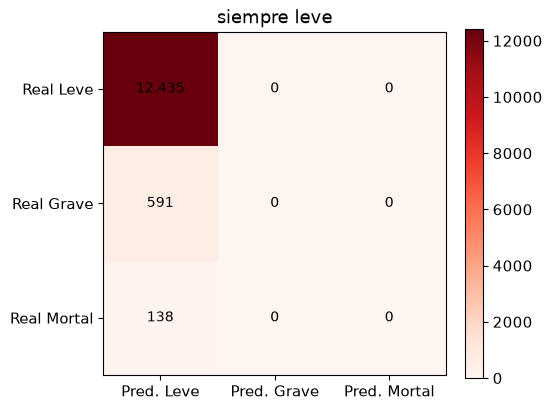

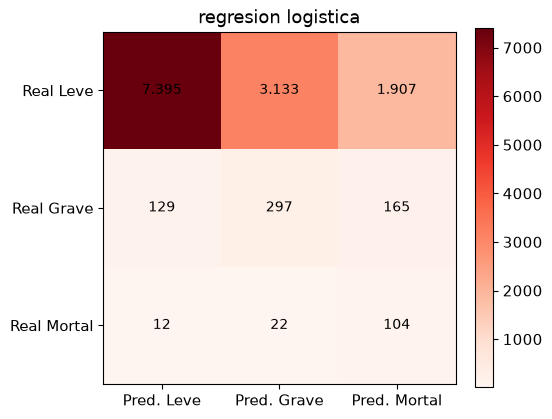

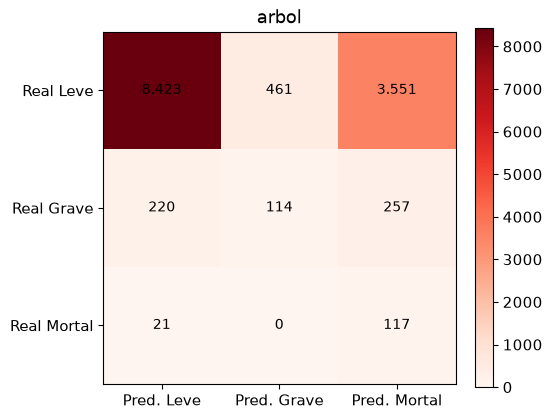

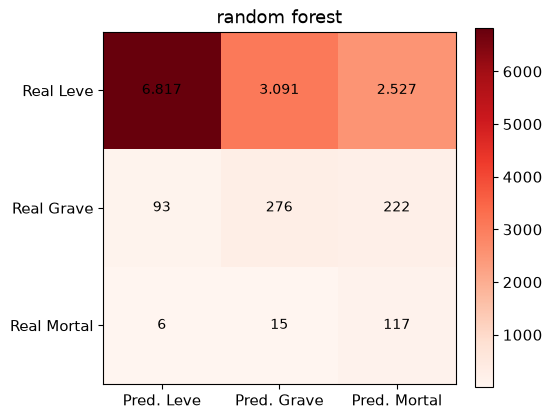

In [4]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
})
ETIQUETAS = ["Leve", "Grave", "Mortal"]

def dibujar_matriz(nombre, pred, archivo):
    matriz = confusion_matrix(y_test, pred, labels=NIVELES)
    figura, eje = plt.subplots(figsize=(5.4, 4.6))
    imagen = eje.imshow(matriz, cmap="Reds")
    eje.set_xticks([0, 1, 2], [f"Pred. {nombre_nivel}" for nombre_nivel in ETIQUETAS])
    eje.set_yticks([0, 1, 2], [f"Real {nombre_nivel}" for nombre_nivel in ETIQUETAS])
    eje.set_title(nombre.replace("_", " "))
    for i in range(3):
        for j in range(3):
            eje.text(
                j, i, f"{matriz[i, j]:,}".replace(",", "."),
                ha="center", va="center", color="black", fontsize=10,
            )
    figura.colorbar(imagen, ax=eje, fraction=0.046)
    figura.tight_layout()
    figura.savefig(FIGURAS / archivo, dpi=140, bbox_inches="tight")
    plt.show()
    return matriz

matrices = {}
for nombre, pred in predicciones.items():
    matrices[nombre] = dibujar_matriz(nombre, pred, f"06_matriz_{nombre}.png").tolist()


## Cuál se queda

Se ordena por el recall macro: el promedio del recall de leve, de grave y de mortal. Si dos empatan, desempata el recall del mortal y después el del grave. El acierto no entra en la elección.


In [5]:
elegido = tabla.iloc[0]["modelo"]
print("Modelo elegido:", elegido)
print(tabla.round(3).to_string(index=False))

salida = {
    "elegido": elegido,
    "clases": NIVELES,
    "criterio": "mayor recall macro en la prueba; desempate por recall del mortal y después del grave",
    "hiperparametros": {
        "regresion_logistica": {"max_iter": 1000, "class_weight": "pesos del entrenamiento", "random_state": 42},
        "arbol": {"max_depth": 5, "min_samples_leaf": 20, "class_weight": "pesos del entrenamiento", "random_state": 42},
        "random_forest": {
            "n_estimators": 200,
            "max_depth": 8,
            "min_samples_leaf": 10,
            "class_weight": "pesos del entrenamiento",
            "random_state": 42,
        },
    },
    "prueba": {
        "filas": int(len(y_test)),
        "por_nivel": {nivel: int((y_test == nivel).sum()) for nivel in NIVELES},
    },
    "modelos": filas,
    "matrices": matrices,
}
ruta = ROOT / "data" / "preprocesado" / "modelos.json"
ruta.write_text(json.dumps(salida, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Guardado en", ruta)


Modelo elegido: random_forest
             modelo  acierto  recall_macro  f1_macro  recall_leve  recall_grave  recall_mortal  precision_grave  precision_mortal  f1_grave  f1_mortal
      random_forest    0.548         0.621     0.307        0.548         0.467          0.848            0.082             0.041     0.139      0.078
regresion_logistica    0.592         0.617     0.326        0.595         0.503          0.754            0.086             0.048     0.147      0.090
              arbol    0.657         0.573     0.351        0.677         0.193          0.848            0.198             0.030     0.196      0.058
       siempre_leve    0.945         0.333     0.324        1.000         0.000          0.000            0.000             0.000     0.000      0.000
Guardado en D:\Cositas\Progra\sistemas-inteligentes-uni\siniestros-viales-predictor\data\preprocesado\modelos.json
